# OP-FL v2 — 05. Raccourci du masque et masquage contrôlé du label

**Question.** Quand chaque hôpital observe le label selon sa propre politique de dosage, un modèle fédéré apprend-il
l'état clinique, ou la politique de dosage ? Et cela change-t-il ce que le modèle apprend sur des hôpitaux jamais vus ?

Ce notebook **ne propose pas encore de méthode**. Il vérifie d'abord que le biais existe sur des hôpitaux tenus à l'écart (expérience A)
et qu'une référence d'évaluation crédible est disponible (expérience B). La méthode (notebook 06) ne sera développée que si ces deux points sont établis.

**Cas principal : hyperlactatémie** (lactate ≥ 4 mmol/L entre 24 h et 72 h ; examen prescrit sur suspicion).
**Contraste : AKI** (créatinine ; examen de routine). Définitions et population identiques au notebook 04 (séjours encore en réanimation à 48 h, hôpitaux de développement).

| Codage | Définition | Statut |
|---|---|---|
| « non dosé = négatif » (`neg`) | 1 si un dosage dépasse le seuil, 0 sinon (y compris sans dosage) | **convention opérationnelle** fréquente, pas une définition clinique validée |
| cas complets (`cc`) | défini seulement si l'examen est redosé après 24 h | élimine les non-dosés, mais la population restante est **sélectionnée** (plus grave) |

**Pas de fuite temporelle.** Entrées : fenêtre [0, 24 h[ (24 pas horaires, y compris le masque M). Labels : dosages à partir de 24 h. Contrôlé à l'étape 10.
**Séparation des hôpitaux.** Plis *leave-hospitals-out* du protocole figé ; réglages d'entraînement repris du notebook 02 sans aucun nouveau choix d'hyperparamètre ; test verrouillé jamais chargé.

---

### Expérience A — le masque apprend-il la politique de dosage ? (labels réels, 60 hôpitaux, 5 plis)

Modèles FedAvg (GRU, réglages du notebook 02) : `x_only` (physiologie, sans masque), `x_obs` (physiologie + masque), `obs_only` (masque seul).
Entraînés sur le label `neg` ou sur le label `cc` (patients redosés seulement). Évalués sur les hôpitaux tenus à l'écart (`val + test`) avec trois cibles :
le label enregistré (`neg`), le label chez les patients redosés (`cc`, population sélectionnée), et **le fait d'être redosé** (D).

### Expérience B — masquage contrôlé, référence connue (20 hôpitaux qui dosent le plus)

Dans les hôpitaux du tiers « haut » d'intensité de dosage du lactate (critère sans label), le label **avant masquage** sert de référence.
Pour les hôpitaux d'entraînement, on applique la politique d'un hôpital réel du tiers « moyen » ou « bas » :
1. **qui est redosé** : un patient redosé dans l'hôpital k le reste avec la probabilité π_j(x) / π_k(x), où π est un modèle commun de redosage (variables des 24 h, y compris le masque) avec un décalage propre à chaque hôpital (notebook 04) ;
2. **combien de fois** : le premier dosage est gardé, les suivants avec la probabilité (intensité de j) / (intensité de k).

Les labels sont recalculés après masquage ; les hôpitaux tenus à l'écart sont évalués avec le label **avant masquage**.

**Cible de référence.** Ce n'est pas l'état clinique (jamais observé chez un patient non dosé), mais **« hyperlactatémie détectée sous une politique de dosage dense »** :
un label standardisé sur la politique des hôpitaux qui dosent le plus. Il suppose qu'un patient non dosé dans ces hôpitaux est le plus souvent réellement négatif.

Limites : la politique simulée ne dépend que de ce qui est observé (x) ; la part du choix clinique qui dépend d'informations absentes des données n'est pas reproduite.
C'est une expérience contrôlée de sensibilité, pas une reproduction du fonctionnement réel d'un hôpital.

---

### Critères fixés avant les résultats (étape 9)

Statistiques calculées sur les prédictions moyennées sur les seeds ; IC à 95 % par bootstrap sur les hôpitaux (1000 tirages).

| Code | Question | Mesure | Rempli si |
|---|---|---|---|
| **A1** | Le masque aide-t-il surtout à prédire le label enregistré ? | modèles entraînés sur `neg` : [AUROC_neg(x_obs) − AUROC_neg(x_only)] − [AUROC_cc(x_obs) − AUROC_cc(x_only)] (AUROC_cc chez les redosés) | borne basse de l'IC > 0 |
| **A2** | Le masque sert-il à prédire le dosage plutôt que l'état ? | gain du masque pour prédire D [AUROC_D(x_obs) − AUROC_D(x_only)] : entraîné sur `neg` − entraîné sur `cc` | borne basse de l'IC > 0 |
| **B1** | La politique de dosage change-t-elle ce que le modèle apprend (classement, pas seulement le niveau de risque) ? | AUROC de référence de `x_obs` (`neg`) : politiques du tiers bas − référence | ≤ −0,02 et borne haute de l'IC < 0 |
| **B2** | Le masque amplifie-t-il la perte ? | perte de `x_obs` − perte de `x_only` (tiers bas, `neg`) | borne haute de l'IC < 0 (descriptif pour le verdict : mécanisme) |
| **B3** | Les cas complets suffisent-ils ? | AUROC de référence : `x_obs` entraîné en `cc` sous politiques du tiers bas − `x_obs` entraîné en `neg` sur la référence | borne basse de l'IC > −0,01 → les cas complets atteignent la référence |

Un score entraîné sur `neg` prédit forcément en partie le dosage (le label vaut D × Y) : A2 compare donc le **gain apporté par le masque** dans les deux régimes, pour isoler ce que le masque ajoute.
B3 compare à la meilleure option simple sous la politique de référence ; l'écart `cc` − `neg` **sans masquage** est donné à titre descriptif.

Le critère principal de B porte sur la **discrimination** : une perte limitée au niveau moyen du risque relèverait de la calibration, déjà traitée par RECAP-FL et SiteCal. Le rapport observé / prédit est donné à titre descriptif.

| Verdict | Condition | Suite |
|---|---|---|
| **GO MÉTHODE** | B1 et non B3 | notebook 06 : méthode OP-FL (événement × détection) |
| **CAS COMPLETS SUFFISENT** | B1 et B3 | la méthode apporterait peu ; article de caractérisation + recommandation |
| **RACCOURCI SANS PERTE DE CLASSEMENT** | non B1, et A1 ou A2 | le biais touche surtout le niveau de risque (proche de la calibration) : à discuter |
| **PLAN B** | sinon | article de caractérisation (notebook 04) |

## Étape 0 — Configuration

Les réglages d'entraînement (`CFG`) sont **ceux du notebook 02** ; la cellule vérifie qu'ils n'ont pas changé.
`SEEDS` : 5 seeds pour les résultats définitifs. Pour un premier passage, mettez `[11, 22, 33]` : la boucle de l'étape 6 complétera plus tard les seeds manquantes sans refaire les autres.

In [1]:
# ============================================================
# ÉTAPE 0 — CONFIGURATION
# ============================================================
import sys, os, json, time, importlib
from pathlib import Path
import numpy as np
import pandas as pd
import torch

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 200)

PROJECT_DIR = Path("..")
DATA_DIR = PROJECT_DIR / "data_v1"
SRC_DIR = PROJECT_DIR / "src"
RES04 = PROJECT_DIR / "results" / "04_observation_label"
RES_DIR = PROJECT_DIR / "results" / "05_raccourci_masquage"
PRED_DIR, HIST_DIR, FIG_DIR = RES_DIR / "preds", RES_DIR / "history", RES_DIR / "figures"
for d in (PRED_DIR, HIST_DIR, FIG_DIR):
    d.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(SRC_DIR.resolve()))

EXPECTED_PROTOCOL_HASH = "d92099ea7c11d517"
protocol = json.loads((DATA_DIR / "splits" / "protocol.json").read_text(encoding="utf-8"))
assert protocol["hash"] == EXPECTED_PROTOCOL_HASH, f"Protocole inattendu ({protocol['hash']})."
DEV = sorted(int(h) for k in protocol["folds"] for h in protocol["folds"][k])
LOCKED = set(protocol["locked_test_hospitals"])
assert (RES04 / "stay_labels.parquet").exists(), "Exécuter d'abord le notebook 04 (étapes 0 à 3)."
cfg04 = json.loads((RES04 / "config.json").read_text(encoding="utf-8"))
assert cfg04["protocol_hash"] == protocol["hash"]
WIN, LAC_END, LAC_THR = 1440, cfg04["lac_end"], cfg04["lac_thr"]

FOLDS = [0, 1, 2, 3, 4]
SEEDS = [11, 22, 33, 44, 55]
CFG = {"rounds": 30, "client_frac": 0.5, "local_epochs": 1, "lr": 1e-3, "batch_size": 64,
       "hidden": 64, "head": 32, "dropout": 0.1, "grad_clip": 1.0}
cfg02_path = PROJECT_DIR / "results" / "02_baselines" / "config.json"
if cfg02_path.exists():
    assert json.loads(cfg02_path.read_text(encoding="utf-8"))["cfg"] == CFG, "CFG différent du notebook 02."

A_MODELS = ["x_only", "x_obs", "obs_only"]
B_MODELS = ["x_only", "x_obs"]
B_SCENARIOS = ["ref", "mid", "low"]          # référence, politiques du tiers moyen, du tiers bas
CONFIGS = {}
for reg in ("neg", "cc"):
    for m in A_MODELS:
        CONFIGS[f"A_lac_{reg}_{m}"] = {"exp": "A", "label": "lac", "regime": reg, "model": m}
for m in A_MODELS:
    CONFIGS[f"A_aki_neg_{m}"] = {"exp": "A", "label": "aki", "regime": "neg", "model": m}
for sc in B_SCENARIOS:
    for reg in ("neg", "cc"):
        for m in B_MODELS:
            CONFIGS[f"B_{sc}_{reg}_{m}"] = {"exp": "B", "label": "lac", "regime": reg, "model": m, "scenario": sc}

N_BOOT = 1000
CRIT = {"B1_drop": -0.02, "B3_margin": -0.01}
SEED_BOOT = 2026
N_THREADS = max(1, (os.cpu_count() or 2) - 1)
torch.set_num_threads(N_THREADS)
(RES_DIR / "config.json").write_text(json.dumps(
    {"folds": FOLDS, "seeds": SEEDS, "cfg": CFG, "configs": CONFIGS, "n_boot": N_BOOT, "criteria": CRIT,
     "lac_thr": LAC_THR, "lac_end": LAC_END, "protocol_hash": protocol["hash"]}, indent=2), encoding="utf-8")
n_A = sum(c["exp"] == "A" for c in CONFIGS.values()); n_B = len(CONFIGS) - n_A
print(f"PyTorch {torch.__version__} | {N_THREADS} threads | protocole {protocol['hash']}")
print(f"{len(CONFIGS)} configurations (A : {n_A}, B : {n_B}) × {len(FOLDS)} plis × {len(SEEDS)} seeds "
      f"= {len(CONFIGS) * len(FOLDS) * len(SEEDS)} exécutions")

PyTorch 2.9.1+cpu | 3 threads | protocole d92099ea7c11d517
21 configurations (A : 9, B : 12) × 5 plis × 5 seeds = 525 exécutions


## Étape 1 — Module `src/opfl_labelfl.py`

FedAvg avec un label d'entraînement et un poids par patient (poids 0 = pas de label utilisable, par exemple un patient non redosé en cas complets).
Le meilleur round est choisi sur le `val` poolé des hôpitaux d'entraînement **avec les labels d'entraînement** : dans l'expérience B, on n'utilise jamais la référence pour choisir.

In [2]:
# %%writefile ../src/opfl_labelfl.py
# """
# opfl_labelfl — apprentissage fédéré quand le label dépend de la politique de dosage de l'hôpital (OP-FL).

# Généré par notebooks/05_raccourci_masquage.ipynb (étape 1) : modifier le notebook, pas ce fichier.

# - build_fold / restrict : clients d'un pli limités à une population de séjours, éventuellement à certains hôpitaux.
# - set_labels : label d'entraînement y et poids w (0 = label non utilisable) pour les hôpitaux d'entraînement.
# - run_fl : FedAvg (réglages du notebook 02) ; meilleur round sur le val poolé des hôpitaux d'entraînement,
#   avec les labels d'entraînement.
# - degrade_labels : applique à un hôpital k la politique de dosage d'un hôpital j (masquage contrôlé).
# - cluster_boot : IC à 95 % par bootstrap sur les hôpitaux ; auc_sub : AUROC sur un sous-ensemble.
# """
# import copy
# import time
# import numpy as np
# import pandas as pd
# import torch
# import torch.nn.functional as F

# import opfl_data as od
# from opfl_fed import set_seed, fedavg_
# from opfl_models import build_model, n_params, INPUT_KEYS
# from opfl_metrics import auroc
# from opfl_label import summarize_post, threshold_labels


# def _pack(client, keep):
#     return {"X": torch.from_numpy(client["X"][keep]), "M": torch.from_numpy(client["M"][keep]),
#             "D": torch.from_numpy(client["Delta"][keep]), "C": torch.from_numpy(client["C"][keep]),
#             "S": torch.from_numpy(client["S"][keep]), "stay_id": np.asarray(client["stay_id"])[keep]}


# def build_fold(data_dir, fold, population, mode="global"):
#     """Hôpitaux d'entraînement : train / val / test ; hôpitaux tenus à l'écart : valtest. Séjours limités à `population`."""
#     if str(fold) == "final":
#         raise ValueError("Le test verrouillé ne se charge pas ici.")
#     norm = od.load_normalizer(data_dir, fold)
#     tr, ho = od.fold_hospitals(data_dir, fold)
#     train_h, held_h = [int(h) for h in tr], [int(h) for h in ho]
#     locked = set(od.load_protocol(data_dir)["locked_test_hospitals"])
#     if locked & set(train_h + held_h) or set(train_h) & set(held_h):
#         raise ValueError("Hôpitaux du pli incohérents.")
#     pop = np.asarray(sorted(int(s) for s in population))
#     codes = od.SPLIT_CODES
#     clients = {}
#     for h in train_h + held_h:
#         c = od.load_client(data_dir, h, norm, mode=mode)
#         inpop = np.isin(c["stay_id"], pop)
#         if h in train_h:
#             clients[h] = {s: _pack(c, inpop & (c["split"] == codes[s])) for s in ("train", "val", "test")}
#         else:
#             clients[h] = {"valtest": _pack(c, inpop & np.isin(c["split"], [codes["val"], codes["test"]]))}
#     ref = clients[train_h[0]]["train"]
#     return {"fold": int(fold), "train_h": train_h, "held_h": held_h, "clients": clients,
#             "n_feat": int(ref["X"].shape[2]), "n_static": int(ref["S"].shape[1])}


# def restrict(fd, hospitals):
#     hs = {int(h) for h in hospitals}
#     return {**fd, "train_h": [h for h in fd["train_h"] if h in hs], "held_h": [h for h in fd["held_h"] if h in hs]}


# def set_labels(fd, y, w):
#     """y, w : Series indexées par stay_id. Label manquant (NaN) => poids 0."""
#     y, w = pd.Series(y).astype(float), pd.Series(w).astype(float)
#     for h in fd["train_h"]:
#         for s in ("train", "val", "test"):
#             p = fd["clients"][h][s]
#             yy = y.reindex(p["stay_id"]).to_numpy(np.float32)
#             ww = w.reindex(p["stay_id"]).to_numpy(np.float32)
#             ww = np.where(np.isnan(yy) | np.isnan(ww), 0.0, ww).astype(np.float32)
#             p["y"] = torch.from_numpy(np.nan_to_num(yy, nan=0.0).astype(np.float32))
#             p["w"] = torch.from_numpy(ww)


# @torch.no_grad()
# def predict(model, data, batch_size=4096):
#     model.eval()
#     n = len(data["stay_id"])
#     if n == 0:
#         return np.zeros(0, np.float32)
#     out = [torch.sigmoid(model(*[data[k][i:i + batch_size] for k in INPUT_KEYS])) for i in range(0, n, batch_size)]
#     return torch.cat(out).numpy()


# def local_train(model, data, cfg, gen):
#     lab = torch.nonzero(data["w"] > 0).flatten()
#     n = len(lab)
#     if n == 0:
#         return np.nan, 0
#     model.train()
#     opt = torch.optim.Adam(model.parameters(), lr=cfg["lr"])
#     total = 0.0
#     for _ in range(cfg["local_epochs"]):
#         perm = lab[torch.randperm(n, generator=gen)]
#         for i in range(0, n, cfg["batch_size"]):
#             idx = perm[i:i + cfg["batch_size"]]
#             logit = model(*[data[k][idx] for k in INPUT_KEYS])
#             loss = F.binary_cross_entropy_with_logits(logit, data["y"][idx])
#             opt.zero_grad()
#             loss.backward()
#             torch.nn.utils.clip_grad_norm_(model.parameters(), cfg["grad_clip"])
#             opt.step()
#             total += float(loss.item()) * len(idx)
#     return total / (n * cfg["local_epochs"]), n


# def run_fl(fd, model_name, seed, cfg, verbose=True):
#     set_seed(seed)
#     model = build_model(model_name, fd["n_feat"], fd["n_static"], cfg["hidden"], cfg["head"], cfg["dropout"])
#     rng = np.random.default_rng(seed)
#     gen = torch.Generator().manual_seed(seed)
#     C, train_h = fd["clients"], fd["train_h"]
#     n_sel = max(1, int(round(cfg["client_frac"] * len(train_h))))
#     vmask = [C[h]["val"]["w"].numpy() > 0 for h in train_h]
#     y_val = np.concatenate([C[h]["val"]["y"].numpy()[m] for h, m in zip(train_h, vmask)])
#     best_auc, best_state, best_round, hist = -np.inf, None, 0, []
#     for r in range(1, cfg["rounds"] + 1):
#         t0 = time.time()
#         states, weights, losses = [], [], []
#         for h in rng.choice(train_h, size=n_sel, replace=False):
#             local = copy.deepcopy(model)
#             loss, n = local_train(local, C[int(h)]["train"], cfg, gen)
#             if n > 0:
#                 states.append(local.state_dict()); weights.append(n); losses.append(loss)
#         if states:
#             fedavg_(model, states, weights)
#         p_val = np.concatenate([predict(model, C[h]["val"])[m] for h, m in zip(train_h, vmask)])
#         va = auroc(y_val, p_val)
#         hist.append({"round": r, "train_loss": float(np.average(losses, weights=weights)) if states else np.nan,
#                      "val_auroc": va, "seconds": time.time() - t0})
#         if np.isfinite(va) and va > best_auc:
#             best_auc, best_state, best_round = va, copy.deepcopy(model.state_dict()), r
#         if verbose:
#             print(f"    round {r:2d}/{cfg['rounds']} | AUROC val {va:.4f} | {hist[-1]['seconds']:.1f} s   ", end="\r")
#     if verbose:
#         print()
#     if best_state is None:                     # val sans les deux classes : dernier round
#         best_round = cfg["rounds"]
#     else:
#         model.load_state_dict(best_state)
#     rows = []
#     def add(h, data, role):
#         rows.append(pd.DataFrame({"stay_id": data["stay_id"], "hospitalid": h, "role": role,
#                                   "p": predict(model, data).astype(np.float32)}))
#     for h in train_h:
#         add(h, C[h]["val"], "val")
#         add(h, C[h]["test"], "intra")
#     for h in fd["held_h"]:
#         add(h, C[h]["valtest"], "transfer")
#     info = {"best_round": best_round, "best_val_auroc": float(best_auc), "n_params": n_params(model),
#             "n_train_labelled": int(sum(float(C[h]["train"]["w"].sum()) for h in train_h)),
#             "seconds": float(sum(x["seconds"] for x in hist))}
#     return pd.concat(rows, ignore_index=True), pd.DataFrame(hist), info


# def degrade_labels(post, stays, assign, lp, offset, rate_t, thr, rng):
#     """
#     Applique aux hôpitaux k de `assign` la politique de dosage de l'hôpital assign[k].
#     post : dosages [stay_id, offset, value] de la fenêtre du label ; stays : DataFrame indexé par stay_id (hospitalid).
#     lp : score linéaire du modèle commun de redosage ; offset : décalage par hôpital ; rate_t : dosages / jour chez les redosés.
#     Un patient redosé reste redosé avec la probabilité min(1, π_j / π_k) ; son premier dosage est gardé, les suivants
#     avec la probabilité min(1, intensité_j / intensité_k). On ne peut que retirer des dosages, jamais en ajouter.
#     """
#     sig = lambda z: 1.0 / (1.0 + np.exp(-np.clip(z, -30, 30)))
#     sub = stays[stays["hospitalid"].isin(list(assign))]
#     k = sub["hospitalid"].to_numpy()
#     j = np.array([assign[int(h)] for h in k])
#     z = lp.reindex(sub.index).to_numpy()
#     q = np.minimum(1.0, sig(z + offset.reindex(j).to_numpy()) / sig(z + offset.reindex(k).to_numpy()))
#     kept = sub.index[rng.random(len(sub)) < q]
#     m = post[post["stay_id"].isin(kept)].sort_values(["stay_id", "offset"], kind="stable")
#     first = ~m["stay_id"].duplicated().to_numpy()
#     hk = m["stay_id"].map(sub["hospitalid"])
#     ratio = np.minimum(1.0, rate_t.reindex(hk.map(assign)).to_numpy() / rate_t.reindex(hk).to_numpy())
#     m = m[first | (rng.random(len(m)) < ratio)]
#     s = summarize_post(m, sub.index)
#     obs, cc, neg = threshold_labels(s["peak"], s["n_post"], thr)
#     return pd.DataFrame({"hospitalid": k, "policy_of": j, "q": q, "obs": obs, "y_cc": cc, "y_neg": neg}, index=sub.index)


# def auc_sub(y, p, idx, mask=None):
#     y, p = np.asarray(y, float)[idx], np.asarray(p, float)[idx]
#     keep = ~np.isnan(y)
#     if mask is not None:
#         keep &= np.asarray(mask, bool)[idx]
#     return auroc(y[keep], p[keep])


# def cluster_boot(groups, stat, n_boot=1000, seed=0):
#     """stat(idx) -> float. Rééchantillonne les hôpitaux (groupes) avec remise. Renvoie (estimation, IC bas, IC haut)."""
#     groups = np.asarray(groups)
#     uniq = np.unique(groups)
#     members = [np.flatnonzero(groups == g) for g in uniq]
#     est = float(stat(np.arange(len(groups))))
#     rng = np.random.default_rng(seed)
#     bs = np.array([stat(np.concatenate([members[i] for i in rng.integers(0, len(uniq), len(uniq))]))
#                    for _ in range(n_boot)], float)
#     lo, hi = np.nanpercentile(bs, [2.5, 97.5])
#     return est, float(lo), float(hi)

## Étape 2 — Population, labels et tiers d'intensité de dosage

Population et labels repris du notebook 04 (`stay_labels.parquet`). On ajoute :
* `hyper24` : lactate déjà ≥ 4 mmol/L dans les 24 premières heures (sous-groupe « nouvelle hyperlactatémie » = `hyper24` faux) ;
* les dosages de lactate de la fenêtre du label (pour le masquage de l'expérience B), avec un contrôle : ils redonnent exactement les labels du notebook 04 ;
* les tiers d'hôpitaux selon l'intensité de dosage du lactate (dosages par jour de présence ; critère sans label, même définition qu'au notebook 04).

In [3]:
# ============================================================
# ÉTAPE 2 — POPULATION, LABELS ET TIERS D'INTENSITÉ
# ============================================================
import opfl_data as od, opfl_metrics, opfl_label, opfl_fed, opfl_labelfl
for m in (od, opfl_metrics, opfl_label, opfl_fed, opfl_labelfl):
    importlib.reload(m)
from opfl_metrics import auroc, auprc
from opfl_label import summarize_post, threshold_labels, site_offset
from opfl_labelfl import build_fold, restrict, set_labels, run_fl, degrade_labels, auc_sub, cluster_boot

st = pd.read_parquet(RES04 / "stay_labels.parquet")
st = st[st["present48"]].set_index("stay_id").sort_index()
assert set(st["hospitalid"]) <= set(DEV) and LOCKED.isdisjoint(set(st["hospitalid"]))
labs = pd.read_parquet(RES04 / "label_labs.parquet")
lac = labs[(labs["var"] == "lactate") & labs["stay_id"].isin(st.index)]
st["hyper24"] = (lac[lac["offset"] < WIN].groupby("stay_id")["value"].max().reindex(st.index) >= LAC_THR).to_numpy()
stop = np.minimum(lac["stay_id"].map(st["unitdischargeoffset"]), LAC_END)
POST_LA = lac[(lac["offset"] >= WIN) & (lac["offset"] <= stop)][["stay_id", "offset", "value"]].reset_index(drop=True)
s_chk = summarize_post(POST_LA, st.index)
same_labels = bool(np.array_equal(s_chk["n_post"].to_numpy(), st["la_n_post"].to_numpy())
                   and np.array_equal(threshold_labels(s_chk["peak"], s_chk["n_post"], LAC_THR)[2], st["hyper_neg"].to_numpy()))
print("Dosages de la fenêtre du label identiques au notebook 04 :", same_labels)

R_H = st.groupby("hospitalid")["la_rate"].mean()
q1, q2 = R_H.quantile([1 / 3, 2 / 3])
TERC = pd.Series(np.where(R_H >= q2, "haut", np.where(R_H <= q1, "bas", "moyen")), index=R_H.index)
DENSE = sorted(int(h) for h in TERC.index[TERC == "haut"])
MID = sorted(int(h) for h in TERC.index[TERC == "moyen"])
LOW = sorted(int(h) for h in TERC.index[TERC == "bas"])
st["tercile"] = st["hospitalid"].map(TERC)
st["has_cr_base"] = st["cr_base"].notna()

summ = st.groupby("tercile").agg(
    hopitaux=("hospitalid", "nunique"), sejours=("hospitalid", "size"),
    dosages_par_jour=("la_rate", "mean"), lactate_redose=("obs_la", "mean"),
    evenements_neg=("hyper_neg", "sum"), prevalence_neg=("hyper_neg", "mean"), prevalence_cc=("hyper_cc", "mean"),
    hyper24=("hyper24", "mean")).reindex(["haut", "moyen", "bas"])
display(summ.round(4))
print(f"Population : {len(st)} séjours présents à 48 h ({int(st['has_cr_base'].sum())} avec créatinine de base pour l'AKI)")
print(f"Lactate : {int(st['hyper_neg'].sum())} événements (non dosé = négatif) ; {int(st['obs_la'].sum())} patients redosés")

Dosages de la fenêtre du label identiques au notebook 04 : True


,hopitaux,sejours,dosages_par_jour,lactate_redose,evenements_neg,prevalence_neg,prevalence_cc,hyper24
tercile,,,,,,,,
haut,20,11139,0.3900,0.2764,454.0,0.0408,0.1475,0.1002
moyen,20,13451,0.1675,0.1618,340.0,0.0253,0.1562,0.0651
bas,20,13688,0.0575,0.0674,149.0,0.0109,0.1614,0.0337


Population : 38278 séjours présents à 48 h (35814 avec créatinine de base pour l'AKI)
Lactate : 943 événements (non dosé = négatif) ; 6179 patients redosés


## Étape 3 — Politiques de dosage pour le masquage contrôlé (expérience B)

Modèle commun de redosage du lactate (régression logistique sur les variables des 24 h, **y compris** les indicateurs d'observation, car le dosage réel en dépend) ;
décalage propre à chaque hôpital ; intensité de dosage chez les patients redosés.
Contrôles : appliquer à un hôpital sa **propre** politique ne change rien ; appliquer une autre politique ne fait que retirer des événements.

In [4]:
# ============================================================
# ÉTAPE 3 — POLITIQUES DE DOSAGE POUR LE MASQUAGE CONTRÔLÉ
# ============================================================
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

norm_f = od.load_normalizer(DATA_DIR, "final")
parts = []
for h in DEV:
    cl = od.load_client(DATA_DIR, h, norm_f, mode="global")
    arr = np.concatenate([cl["X"][:, -1, :], cl["M"].mean(axis=1), cl["C"].sum(axis=1), cl["S"]], axis=1)
    parts.append(pd.DataFrame(arr, index=cl["stay_id"]))
FX = pd.concat(parts).loc[st.index]
tr = (st["split"] == "train").to_numpy()
d_obs = st["obs_la"].to_numpy().astype(int)
prop = make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000, C=0.1)).fit(FX.to_numpy()[tr], d_obs[tr])
LP = pd.Series(prop.decision_function(FX.to_numpy()), index=st.index)
OFFSET = pd.Series({int(h): site_offset(LP.to_numpy()[idx], d_obs[idx])[0] for h, idx in st.groupby("hospitalid").indices.items()})
RATE_T = st[st["obs_la"]].groupby("hospitalid")["la_rate"].mean().reindex(R_H.index)
RATE_T = RATE_T.fillna(RATE_T.median())
print(f"Modèle de redosage : AUROC val + test = {auroc(d_obs[~tr], LP.to_numpy()[~tr]):.3f}")
pol = pd.DataFrame({"tiers": TERC, "intensite": R_H, "decalage": OFFSET, "intensite_chez_redoses": RATE_T})
pol.to_csv(RES_DIR / "politiques.csv")
display(pol.groupby("tiers")[["intensite", "decalage", "intensite_chez_redoses"]].agg(["mean", "min", "max"]).round(3))

base = st.loc[st["hospitalid"].isin(DENSE)]
ident = degrade_labels(POST_LA, st, {h: h for h in DENSE}, LP, OFFSET, RATE_T, LAC_THR, np.random.default_rng(0))
IDENTITY_OK = bool(np.array_equal(ident["y_neg"].to_numpy(), base["hyper_neg"].to_numpy())
                   and np.array_equal(ident["obs"].to_numpy(), base["obs_la"].to_numpy()))
rows, MONO_OK = [], True
for sc, pool in [("mid", MID), ("low", LOW)]:
    rng = np.random.default_rng(SEED_BOOT)
    dem = degrade_labels(POST_LA, st, {h: int(rng.choice(pool)) for h in DENSE}, LP, OFFSET, RATE_T, LAC_THR, rng)
    MONO_OK &= bool((dem["y_neg"].to_numpy() <= base["hyper_neg"].to_numpy()).all()
                    and (dem["obs"].to_numpy() <= base["obs_la"].to_numpy()).all())
    rows.append({"scenario": sc, "redoses_avant": base["obs_la"].mean(), "redoses_apres": dem["obs"].mean(),
                 "evenements_avant": int(base["hyper_neg"].sum()), "evenements_apres": int(dem["y_neg"].sum()),
                 "evenements_gardes": dem["y_neg"].sum() / max(base["hyper_neg"].sum(), 1)})
print(f"Politique propre => labels inchangés : {IDENTITY_OK} | masquage => jamais plus d'événements : {MONO_OK}")
print("Exemple de masquage (tous les hôpitaux du tiers haut, une réalisation) :")
display(pd.DataFrame(rows).set_index("scenario").round(4))

Modèle de redosage : AUROC val + test = 0.834


intensite               decalage               intensite_chez_redoses              
           mean    min    max     mean    min    max                   mean    min    max
tiers                                                                                    
bas       0.056  0.008  0.101   -0.742 -1.663  0.056                  0.799  0.501  1.061
haut      0.405  0.229  0.788    0.409 -0.108  1.715                  1.391  0.875  1.979
moyen     0.164  0.105  0.220    0.048 -0.502  0.663                  0.987  0.768  1.329

Politique propre => labels inchangés : True | masquage => jamais plus d'événements : True
Exemple de masquage (tous les hôpitaux du tiers haut, une réalisation) :


,redoses_avant,redoses_apres,evenements_avant,evenements_apres,evenements_gardes
scenario,,,,,
mid,0.2764,0.2222,454,386,0.8502
low,0.2764,0.1572,454,313,0.6894


## Étape 4 — Plan des exécutions et labels d'entraînement

* Expérience A : 60 hôpitaux, plis du protocole. `neg` = tous les patients ; `cc` = patients redosés seulement ; AKI : patients avec créatinine de base.
* Expérience B : hôpitaux du tiers haut seulement (entraînement et évaluation), plis du protocole restreints à ces hôpitaux.
  Chaque hôpital d'entraînement reçoit la politique d'un hôpital tiré au hasard dans le tiers moyen (`mid`) ou bas (`low`) ; le tirage dépend du pli et de la seed et il est **le même** pour `neg` et `cc` et pour les deux modèles (comparaisons appariées).

In [5]:
# ============================================================
# ÉTAPE 4 — PLAN DES EXÉCUTIONS ET LABELS D'ENTRAÎNEMENT
# ============================================================
SC_CODE = {"mid": 1, "low": 2}
_b_cache = {}

def b_labels(fold, seed, scenario, train_dense):
    key = (fold, seed, scenario, tuple(train_dense))
    if key not in _b_cache:
        base_ = st.loc[st["hospitalid"].isin(train_dense)]
        if scenario == "ref":
            lab = pd.DataFrame({"hospitalid": base_["hospitalid"], "policy_of": base_["hospitalid"], "q": 1.0,
                                "obs": base_["obs_la"], "y_cc": base_["hyper_cc"], "y_neg": base_["hyper_neg"]})
        else:
            rng = np.random.default_rng(10_000 * seed + 100 * fold + SC_CODE[scenario])
            pool = MID if scenario == "mid" else LOW
            assign = {int(h): int(rng.choice(pool)) for h in train_dense}
            lab = degrade_labels(POST_LA, st, assign, LP, OFFSET, RATE_T, LAC_THR, rng)
        _b_cache[key] = lab
    return _b_cache[key]

def training_labels(cfg_, fold, seed, train_h):
    neg = cfg_["regime"] == "neg"
    if cfg_["exp"] == "A":
        if cfg_["label"] == "lac":
            return (st["hyper_neg"], pd.Series(1.0, index=st.index)) if neg else (st["hyper_cc"], st["obs_la"].astype(float))
        return st["aki_neg"], st["has_cr_base"].astype(float)
    lab = b_labels(fold, seed, cfg_["scenario"], [h for h in train_h if h in DENSE])
    return (lab["y_neg"], pd.Series(1.0, index=lab.index)) if neg else (lab["y_cc"], lab["obs"].astype(float))

plan = []
for f in FOLDS:
    tr_h, ho_h = od.fold_hospitals(DATA_DIR, f)
    plan.append({"pli": f, "hopitaux_entrainement": len(tr_h), "tenus_a_l_ecart": len(ho_h),
                 "B_entrainement_tiers_haut": len([h for h in tr_h if int(h) in DENSE]),
                 "B_tenus_a_l_ecart_tiers_haut": len([h for h in ho_h if int(h) in DENSE])})
display(pd.DataFrame(plan).set_index("pli"))
display(pd.DataFrame(CONFIGS).T)

,hopitaux_entrainement,tenus_a_l_ecart,B_entrainement_tiers_haut,B_tenus_a_l_ecart_tiers_haut
pli,,,,
0,48,12,15,5
1,48,12,14,6
2,48,12,17,3
3,48,12,18,2
4,48,12,16,4


,exp,label,regime,model,scenario
A_lac_neg_x_only,A,lac,neg,x_only,NaN
A_lac_neg_x_obs,A,lac,neg,x_obs,NaN
A_lac_neg_obs_only,A,lac,neg,obs_only,NaN
A_lac_cc_x_only,A,lac,cc,x_only,NaN
A_lac_cc_x_obs,A,lac,cc,x_obs,NaN
A_lac_cc_obs_only,A,lac,cc,obs_only,NaN
A_aki_neg_x_only,A,aki,neg,x_only,NaN
A_aki_neg_x_obs,A,aki,neg,x_obs,NaN
A_aki_neg_obs_only,A,aki,neg,obs_only,NaN
B_ref_neg_x_only,B,lac,neg,x_only,ref


## Étape 5 — Essai rapide sur le pli 0 et estimation du temps

Deux rounds pour trois configurations représentatives, puis extrapolation. Si la durée est trop longue, réduisez `SEEDS` à 3 dans l'étape 0 pour un premier passage.

In [6]:
# ============================================================
# ÉTAPE 5 — ESSAI RAPIDE + ESTIMATION DU TEMPS
# ============================================================
t0 = time.time()
fd = build_fold(DATA_DIR, FOLDS[0], st.index)
t_load = time.time() - t0
print(f"Pli {FOLDS[0]} chargé en {t_load:.0f} s | {fd['n_feat']} variables temporelles, {fd['n_static']} statiques")
sec = {}
for name in ["A_lac_neg_x_obs", "A_lac_cc_x_obs", "B_low_neg_x_obs"]:
    c_ = CONFIGS[name]
    fdx = fd if c_["exp"] == "A" else restrict(fd, DENSE)
    y, w = training_labels(c_, fd["fold"], SEEDS[0], fdx["train_h"])
    set_labels(fdx, y, w)
    _, hist, info = run_fl(fdx, c_["model"], SEEDS[0], {**CFG, "rounds": 2}, verbose=False)
    sec[name] = float(hist["seconds"].mean())
    print(f"  {name:18s} : {sec[name]:.1f} s par round | {info['n_train_labelled']} patients labellisés (train)")
del fd, fdx
_b_cache.clear()

def sec_of(c_):
    if c_["exp"] == "B":
        return sec["B_low_neg_x_obs"]
    return sec["A_lac_cc_x_obs"] if c_["regime"] == "cc" else sec["A_lac_neg_x_obs"]
total = (sum(sec_of(c_) for c_ in CONFIGS.values()) * CFG["rounds"] * len(SEEDS) + t_load) * len(FOLDS)
print(f"\nDurée estimée de l'étape 6 : {total / 3600:.1f} h ({len(CONFIGS)} configurations × {len(FOLDS)} plis × "
      f"{len(SEEDS)} seeds × {CFG['rounds']} rounds)")

Pli 0 chargé en 9 s | 29 variables temporelles, 21 statiques
  A_lac_neg_x_obs    : 9.6 s par round | 21745 patients labellisés (train)
  A_lac_cc_x_obs     : 3.1 s par round | 3567 patients labellisés (train)
  B_low_neg_x_obs    : 1.3 s par round | 5814 patients labellisés (train)

Durée estimée de l'étape 6 : 17.3 h (21 configurations × 5 plis × 5 seeds × 30 rounds)


## Étape 6 — Boucle principale (reprise automatique)

Une exécution déjà terminée n'est jamais refaite : si la cellule est interrompue, relancez-la et elle reprendra là où elle s'est arrêtée.
Les statistiques de masquage de l'expérience B sont enregistrées dans `degradation_B.csv`.

In [7]:
# ============================================================
# ÉTAPE 6 — BOUCLE PRINCIPALE : CONFIGURATIONS × PLIS × SEEDS
# ============================================================
def pred_path(name, fold, seed):
    return PRED_DIR / f"{name}__fold{fold}__seed{seed}.parquet"

runs_csv, deg_csv = RES_DIR / "runs.csv", RES_DIR / "degradation_B.csv"
n_total = len(CONFIGS) * len(FOLDS) * len(SEEDS)
t_start, n_done_now = time.time(), 0
for fold in FOLDS:
    todo = [(n, s) for s in SEEDS for n in CONFIGS if not pred_path(n, fold, s).exists()]
    if not todo:
        print(f"Pli {fold} : déjà complet.")
        continue
    fd = build_fold(DATA_DIR, fold, st.index)
    fdB = restrict(fd, DENSE)
    _b_cache.clear()
    for name, s in todo:
        c_ = CONFIGS[name]
        fdx = fd if c_["exp"] == "A" else fdB
        y, w = training_labels(c_, fold, s, fdx["train_h"])
        set_labels(fdx, y, w)
        n_existing = sum(pred_path(n, f, ss).exists() for n in CONFIGS for f in FOLDS for ss in SEEDS)
        print(f"[{n_existing + 1}/{n_total}] pli {fold} | {name} | seed {s}")
        preds, hist, info = run_fl(fdx, c_["model"], s, CFG)
        if c_["exp"] == "B" and c_["scenario"] != "ref" and c_["regime"] == "neg" and c_["model"] == B_MODELS[0]:
            lab = b_labels(fold, s, c_["scenario"], [h for h in fdx["train_h"] if h in DENSE])
            ref = st.loc[lab.index]
            pd.DataFrame([{"fold": fold, "seed": s, "scenario": c_["scenario"], "sejours": len(lab),
                           "evenements_ref": int(ref["hyper_neg"].sum()), "evenements_masques": int(lab["y_neg"].sum()),
                           "redoses_ref": int(ref["obs_la"].sum()), "redoses_masques": int(lab["obs"].sum())}]
                         ).to_csv(deg_csv, mode="a", header=not deg_csv.exists(), index=False)
        hist.assign(config=name, fold=fold, seed=s).to_csv(HIST_DIR / f"{name}__fold{fold}__seed{s}.csv", index=False)
        pd.DataFrame([{"config": name, "fold": fold, "seed": s, **info,
                       "finished_at": pd.Timestamp.now().isoformat(timespec="seconds")}]
                     ).to_csv(runs_csv, mode="a", header=not runs_csv.exists(), index=False)
        preds.assign(config=name, fold=fold, seed=s).to_parquet(pred_path(name, fold, s), index=False)   # en dernier
        n_done_now += 1
        left = n_total - sum(pred_path(n, f, ss).exists() for n in CONFIGS for f in FOLDS for ss in SEEDS)
        print(f"    meilleur round {info['best_round']} | AUROC val {info['best_val_auroc']:.4f} | "
              f"{info['seconds'] / 60:.1f} min | reste ≈ {(time.time() - t_start) / n_done_now * left / 3600:.1f} h")
    del fd, fdB

n_files = sum(pred_path(n, f, s).exists() for n in CONFIGS for f in FOLDS for s in SEEDS)
print(f"\nExécutions terminées : {n_files} / {n_total}")

[1/525] pli 0 | A_lac_neg_x_only | seed 11
    round 30/30 | AUROC val 0.8873 | 4.1 s   
    meilleur round 21 | AUROC val 0.8896 | 2.2 min | reste ≈ 20.1 h
[2/525] pli 0 | A_lac_neg_x_obs | seed 11
    round 30/30 | AUROC val 0.9241 | 1.0 s   
    meilleur round 14 | AUROC val 0.9306 | 0.6 min | reste ≈ 10.6 h
[15/525] pli 0 | B_mid_neg_x_obs | seed 11
    round 30/30 | AUROC val 0.9492 | 1.3 s   
    meilleur round 19 | AUROC val 0.9596 | 0.6 min | reste ≈ 10.2 h
[16/525] pli 0 | B_mid_cc_x_only | seed 11
    round 30/30 | AUROC val 0.8893 | 0.5 s   
    meilleur round 29 | AUROC val 0.8893 | 0.2 min | reste ≈ 9.7 h
[17/525] pli 0 | B_mid_cc_x_obs | seed 11
    round 30/30 | AUROC val 0.9178 | 0.4 s   
    meilleur round 30 | AUROC val 0.9178 | 0.2 min | reste ≈ 9.2 h
[18/525] pli 0 | B_low_neg_x_only | seed 11
    round 30/30 | AUROC val 0.9518 | 1.0 s   
    meilleur round 21 | AUROC val 0.9533 | 0.6 min | reste ≈ 9.0 h
[19/525] pli 0 | B_low_neg_x_obs | seed 11
    round 30/30 | A

IOPub message rate exceeded.
The Jupyter server will temporarily stop sending output
to the client in order to avoid crashing it.
To change this limit, set the config variable
`--ServerApp.iopub_msg_rate_limit`.

Current values:
ServerApp.iopub_msg_rate_limit=1000.0 (msgs/sec)
ServerApp.rate_limit_window=3.0 (secs)



    round 30/30 | AUROC val 0.8092 | 1.2 s   
    meilleur round 30 | AUROC val 0.8092 | 0.9 min | reste ≈ 5.1 h
[195/525] pli 1 | A_lac_cc_obs_only | seed 55
    round 30/30 | AUROC val 0.5736 | 2.2 s   
    meilleur round 30 | AUROC val 0.5736 | 0.9 min | reste ≈ 5.1 h
[196/525] pli 1 | A_aki_neg_x_only | seed 55
    round 30/30 | AUROC val 0.6669 | 6.0 s    
    meilleur round 29 | AUROC val 0.6676 | 3.4 min | reste ≈ 5.2 h
[197/525] pli 1 | A_aki_neg_x_obs | seed 55
    round 30/30 | AUROC val 0.8515 | 0.4 s   
    meilleur round 30 | AUROC val 0.8515 | 0.1 min | reste ≈ 4.9 h
[210/525] pli 1 | B_low_cc_x_obs | seed 55
    round 30/30 | AUROC val 0.8381 | 0.3 s   
    meilleur round 30 | AUROC val 0.8381 | 0.2 min | reste ≈ 4.9 h
[211/525] pli 2 | A_lac_neg_x_only | seed 11
    round 30/30 | AUROC val 0.8840 | 3.6 s   
    meilleur round 30 | AUROC val 0.8840 | 2.1 min | reste ≈ 4.9 h
[212/525] pli 2 | A_lac_neg_x_obs | seed 11
    round 30/30 | AUROC val 0.8880 | 4.7 s   
    meil

IOPub message rate exceeded.
The Jupyter server will temporarily stop sending output
to the client in order to avoid crashing it.
To change this limit, set the config variable
`--ServerApp.iopub_msg_rate_limit`.

Current values:
ServerApp.iopub_msg_rate_limit=1000.0 (msgs/sec)
ServerApp.rate_limit_window=3.0 (secs)



## Étape 7 — Expérience A : le masque apprend-il la politique de dosage ?

Hôpitaux tenus à l'écart (`val + test`), tous plis réunis. Prédictions moyennées sur les seeds complètes (mêmes seeds pour toutes les configurations).
* `AUROC_neg` : label enregistré (« non dosé = négatif »), tous les patients.
* `AUROC_cc` : hyperlactatémie chez les patients redosés (population sélectionnée).
* `AUROC_D` : le score prédit-il **le fait d'être redosé** ?
* `AUROC_neg_nouv` : label enregistré chez les patients sans lactate ≥ 4 dans les 24 h (nouvelle hyperlactatémie).

Expérience A — lactate, hôpitaux tenus à l'écart (11509 séjours, 287 événements, 1815 redosés ; seeds [11, 22, 33, 44, 55])


,AUROC_neg,AUROC_neg_par_seed,AUROC_cc,AUROC_D,AUROC_neg_nouv,AUPRC_neg,risque_moyen,prevalence_neg
config,,,,,,,,
A_lac_neg_x_only,0.8827,0.8777 ± 0.0059,0.8152,0.6686,0.7727,0.3903,0.0228,0.0249
A_lac_neg_x_obs,0.8943,0.8909 ± 0.0030,0.8196,0.6991,0.7983,0.4555,0.0206,0.0249
A_lac_neg_obs_only,0.7639,0.7576 ± 0.0106,0.6373,0.6808,0.6501,0.1212,0.0179,0.0249
A_lac_cc_x_only,0.8643,0.8576 ± 0.0018,0.8162,0.6147,0.7458,0.3586,0.0881,0.0249
A_lac_cc_x_obs,0.8963,0.8916 ± 0.0041,0.8257,0.6852,0.8105,0.4264,0.0800,0.0249
A_lac_cc_obs_only,0.7204,0.7011 ± 0.0261,0.6180,0.6499,0.6078,0.1169,0.1398,0.0249


,estimation,IC95_bas,IC95_haut
"gain du masque, label enregistré",0.0115,-0.0029,0.0260
"gain du masque, redosés (cc)",0.0044,-0.0089,0.0201
A1 : différence des gains,0.0071,-0.0007,0.0154
"gain du masque pour prédire D, entraîné sur neg",0.0305,0.0124,0.0484
"gain du masque pour prédire D, entraîné sur cc",0.0705,0.0559,0.0859
A2 : différence des gains pour prédire D,-0.0400,-0.0525,-0.0262
"AUROC_D x_obs, neg − cc (descriptif)",0.0139,0.0010,0.0270


Contraste AKI (entraîné sur « non dosé = négatif ») :


,AUROC_neg,AUROC_cc,AUROC_D
config,,,
A_aki_neg_x_only,0.7031,0.6986,0.6387
A_aki_neg_x_obs,0.7120,0.7073,0.6341
A_aki_neg_obs_only,0.6626,0.6580,0.6014


,estimation,IC95_bas,IC95_haut
"AKI : gain du masque, label enregistré",0.0089,-0.0117,0.0296
"AKI : gain du masque, redosés (cc)",0.0087,-0.0120,0.0296


Spearman (intensité de dosage de l'hôpital, risque moyen prédit), modèles entraînés sur neg : {'x_only': 0.273, 'x_obs': 0.238, 'obs_only': 0.404} | label observé : 0.619


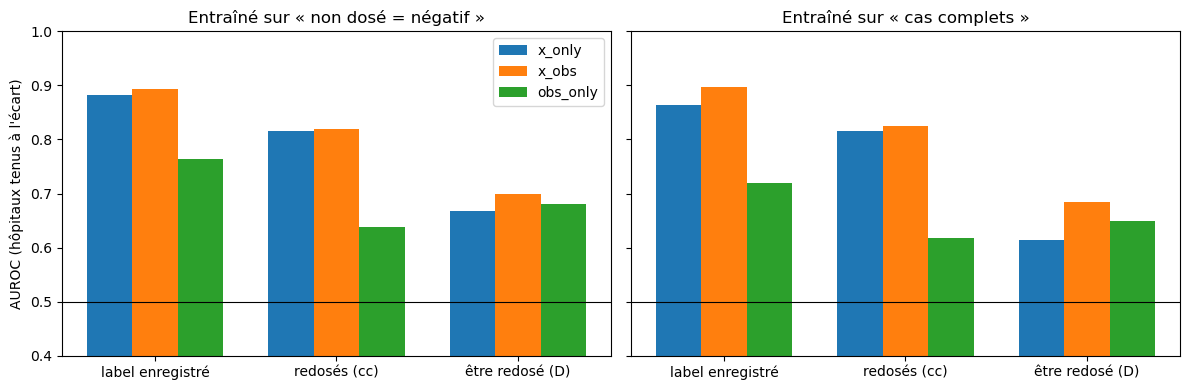

In [8]:
# ============================================================
# ÉTAPE 7 — EXPÉRIENCE A (LABELS RÉELS)
# ============================================================
from scipy import stats
import matplotlib.pyplot as plt

def complete_seeds(names):
    return [s for s in SEEDS if all(pred_path(n, f, s).exists() for n in names for f in FOLDS)]

def load_preds(names, role, seeds):
    df = pd.concat([pd.read_parquet(pred_path(n, f, s)) for n in names for f in FOLDS for s in seeds], ignore_index=True)
    return df[df["role"] == role]

A_lac = [n for n, c_ in CONFIGS.items() if c_["exp"] == "A" and c_["label"] == "lac"]
A_aki = [n for n, c_ in CONFIGS.items() if c_["exp"] == "A" and c_["label"] == "aki"]
SEEDS_A = complete_seeds(A_lac + A_aki)
assert SEEDS_A, "Aucune seed complète pour l'expérience A : exécuter l'étape 6."
dfA = load_preds(A_lac + A_aki, "transfer", SEEDS_A)
WA = dfA.groupby(["stay_id", "config"])["p"].mean().unstack().join(st, how="left")
gA = WA["hospitalid"].to_numpy()
yneg, ycc, Dla = WA["hyper_neg"].to_numpy(float), WA["hyper_cc"].to_numpy(float), WA["obs_la"].to_numpy(float)
new = ~WA["hyper24"].to_numpy(bool)
ALL = np.arange(len(WA))

rowsA = []
for n in A_lac:
    p = WA[n].to_numpy()
    dn = dfA[dfA["config"] == n].merge(st[["hyper_neg"]], left_on="stay_id", right_index=True)
    per_seed = pd.Series([auroc(dn.loc[dn["seed"] == s, "hyper_neg"], dn.loc[dn["seed"] == s, "p"]) for s in SEEDS_A])
    rowsA.append({"config": n, "AUROC_neg": auc_sub(yneg, p, ALL), "AUROC_neg_par_seed": f"{per_seed.mean():.4f} ± {per_seed.std():.4f}",
                  "AUROC_cc": auc_sub(ycc, p, ALL, Dla == 1), "AUROC_D": auc_sub(Dla, p, ALL),
                  "AUROC_neg_nouv": auc_sub(yneg, p, ALL, new), "AUPRC_neg": auprc(yneg, p),
                  "risque_moyen": p.mean(), "prevalence_neg": yneg.mean()})
tabA = pd.DataFrame(rowsA).set_index("config")
tabA.to_csv(RES_DIR / "A_lactate_transfert.csv")
print(f"Expérience A — lactate, hôpitaux tenus à l'écart ({len(WA)} séjours, {int(yneg.sum())} événements, "
      f"{int(Dla.sum())} redosés ; seeds {SEEDS_A})")
display(tabA.round(4))

P = {n: WA[n].to_numpy() for n in A_lac}
def a1(idx):
    t = idx[Dla[idx] == 1]
    g_rec = auroc(yneg[idx], P["A_lac_neg_x_obs"][idx]) - auroc(yneg[idx], P["A_lac_neg_x_only"][idx])
    g_tst = auroc(ycc[t], P["A_lac_neg_x_obs"][t]) - auroc(ycc[t], P["A_lac_neg_x_only"][t])
    return g_rec - g_tst
def g_rec(idx):
    return auroc(yneg[idx], P["A_lac_neg_x_obs"][idx]) - auroc(yneg[idx], P["A_lac_neg_x_only"][idx])
def g_tst(idx):
    t = idx[Dla[idx] == 1]
    return auroc(ycc[t], P["A_lac_neg_x_obs"][t]) - auroc(ycc[t], P["A_lac_neg_x_only"][t])
def gD(reg, idx):
    return auroc(Dla[idx], P[f"A_lac_{reg}_x_obs"][idx]) - auroc(Dla[idx], P[f"A_lac_{reg}_x_only"][idx])
def a2(idx):
    return gD("neg", idx) - gD("cc", idx)
def a2_simple(idx):
    return auroc(Dla[idx], P["A_lac_neg_x_obs"][idx]) - auroc(Dla[idx], P["A_lac_cc_x_obs"][idx])
statsA = {}
for key, fn in [("gain du masque, label enregistré", g_rec), ("gain du masque, redosés (cc)", g_tst),
                ("A1 : différence des gains", a1),
                ("gain du masque pour prédire D, entraîné sur neg", lambda i: gD("neg", i)),
                ("gain du masque pour prédire D, entraîné sur cc", lambda i: gD("cc", i)),
                ("A2 : différence des gains pour prédire D", a2),
                ("AUROC_D x_obs, neg − cc (descriptif)", a2_simple)]:
    statsA[key] = cluster_boot(gA, fn, N_BOOT, SEED_BOOT)
statsA = pd.DataFrame(statsA, index=["estimation", "IC95_bas", "IC95_haut"]).T
statsA.to_csv(RES_DIR / "A_criteres.csv")
display(statsA.round(4))

# contraste AKI (créatinine, examen de routine)
WK = WA[WA["has_cr_base"]]
gK = WK["hospitalid"].to_numpy()
yk_neg, yk_cc, Dk = WK["aki_neg"].to_numpy(float), WK["aki_cc"].to_numpy(float), WK["obs_cr"].to_numpy(float)
PK = {n: WK[n].to_numpy() for n in A_aki}
tabK = pd.DataFrame([{"config": n, "AUROC_neg": auc_sub(yk_neg, PK[n], np.arange(len(WK))),
                      "AUROC_cc": auc_sub(yk_cc, PK[n], np.arange(len(WK)), Dk == 1),
                      "AUROC_D": auc_sub(Dk, PK[n], np.arange(len(WK)))} for n in A_aki]).set_index("config")
kA = {"AKI : gain du masque, label enregistré": cluster_boot(gK, lambda i: auroc(yk_neg[i], PK["A_aki_neg_x_obs"][i]) - auroc(yk_neg[i], PK["A_aki_neg_x_only"][i]), N_BOOT, SEED_BOOT),
      "AKI : gain du masque, redosés (cc)": cluster_boot(gK, lambda i: auc_sub(yk_cc, PK["A_aki_neg_x_obs"], i, Dk == 1) - auc_sub(yk_cc, PK["A_aki_neg_x_only"], i, Dk == 1), N_BOOT, SEED_BOOT)}
kA = pd.DataFrame(kA, index=["estimation", "IC95_bas", "IC95_haut"]).T
tabK.to_csv(RES_DIR / "A_aki_transfert.csv"); kA.to_csv(RES_DIR / "A_aki_gains.csv")
print("Contraste AKI (entraîné sur « non dosé = négatif ») :")
display(tabK.round(4)); display(kA.round(4))

# par hôpital tenu à l'écart : le risque prédit suit-il l'intensité de dosage ?
hosp = WA.groupby("hospitalid").agg(prev_neg=("hyper_neg", "mean"),
                                    **{f"risque_{m}": (f"A_lac_neg_{m}", "mean") for m in A_MODELS})
hosp["intensite"] = R_H.reindex(hosp.index)
rho = {m: stats.spearmanr(hosp["intensite"], hosp[f"risque_{m}"]).statistic for m in A_MODELS}
print("Spearman (intensité de dosage de l'hôpital, risque moyen prédit), modèles entraînés sur neg :",
      {m: round(float(v), 3) for m, v in rho.items()}, f"| label observé : {float(stats.spearmanr(hosp['intensite'], hosp['prev_neg']).statistic):.3f}")
hosp.to_csv(RES_DIR / "A_par_hopital.csv")

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
targets = [("AUROC_neg", "label enregistré"), ("AUROC_cc", "redosés (cc)"), ("AUROC_D", "être redosé (D)")]
for ax, reg in zip(axes, ["neg", "cc"]):
    xs = np.arange(len(targets)); wdt = 0.25
    for i, m in enumerate(A_MODELS):
        ax.bar(xs + (i - 1) * wdt, [tabA.loc[f"A_lac_{reg}_{m}", t] for t, _ in targets], wdt, label=m)
    ax.set_xticks(xs); ax.set_xticklabels([lbl for _, lbl in targets]); ax.axhline(0.5, color="k", lw=0.8)
    ax.set_title(f"Entraîné sur « {'non dosé = négatif' if reg == 'neg' else 'cas complets'} »"); ax.set_ylim(0.4, 1.0)
axes[0].set_ylabel("AUROC (hôpitaux tenus à l'écart)"); axes[0].legend()
plt.tight_layout(); plt.savefig(FIG_DIR / "A_auroc_par_cible.png", dpi=200); plt.show()

## Étape 8 — Expérience B : masquage contrôlé, référence connue

Hôpitaux du tiers haut tenus à l'écart (`val + test`), évalués avec le label **avant masquage** (`AUROC_ref` : hyperlactatémie détectée sous la politique dense ; `AUROC_ref_cc` : chez les patients dosés avant masquage, descriptif).
`O/P` = événements de référence observés / prédits (descriptif : > 1 signifie que le modèle sous-estime le risque).

Expérience B — 20 hôpitaux du tiers haut tenus à l'écart, 3316 séjours, 124 événements de référence ; seeds [11, 22, 33, 44, 55]


,scenario,regime,modele,AUROC_ref,AUROC_ref_cc,AUPRC_ref,O/P
config,,,,,,,
B_ref_neg_x_only,ref,neg,x_only,0.8771,0.8273,0.4047,1.0508
B_ref_neg_x_obs,ref,neg,x_obs,0.8891,0.8388,0.4698,1.0712
B_ref_cc_x_only,ref,cc,x_only,0.8677,0.8403,0.4050,0.4036
B_ref_cc_x_obs,ref,cc,x_obs,0.8921,0.8493,0.4597,0.4618
B_mid_neg_x_only,mid,neg,x_only,0.8755,0.8260,0.4126,1.2180
B_mid_neg_x_obs,mid,neg,x_obs,0.8920,0.8399,0.4733,1.2671
B_mid_cc_x_only,mid,cc,x_only,0.8701,0.8406,0.3969,0.4427
B_mid_cc_x_obs,mid,cc,x_obs,0.8929,0.8478,0.4632,0.4821
B_low_neg_x_only,low,neg,x_only,0.8829,0.8311,0.4257,1.5743


Labels d'entraînement après masquage (somme sur plis et seeds) :


,evenements_ref,evenements_masques,redoses_ref,redoses_masques,evenements_gardes,redoses_gardes
scenario,,,,,,
low,9080,6228,61580,35165,0.686,0.571
mid,9080,7830,61580,51375,0.862,0.834


,estimation,IC95_bas,IC95_haut
"B1 : x_obs neg, bas − référence",0.0063,-0.0177,0.0286
"x_only neg, bas − référence",0.0058,-0.0134,0.0179
"B2 : perte x_obs − perte x_only (bas, neg)",0.0005,-0.0152,0.0162
B3 : x_obs cc (bas) − x_obs neg (référence),0.0034,-0.0200,0.0242
"x_obs neg, moyen − référence",0.0029,-0.0051,0.0088
"x_obs cc, référence − x_obs neg, référence",0.0030,-0.0081,0.0126


B1 par seed : -0.0022 ± 0.0097 (5 seeds)


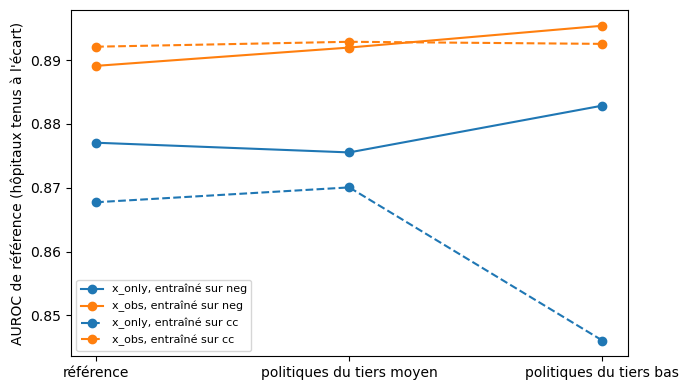

In [9]:
# ============================================================
# ÉTAPE 8 — EXPÉRIENCE B (MASQUAGE CONTRÔLÉ)
# ============================================================
B_names = [n for n, c_ in CONFIGS.items() if c_["exp"] == "B"]
SEEDS_B = complete_seeds(B_names)
assert SEEDS_B, "Aucune seed complète pour l'expérience B : exécuter l'étape 6."
dfB = load_preds(B_names, "transfer", SEEDS_B)
WB = dfB.groupby(["stay_id", "config"])["p"].mean().unstack().join(st, how="left")
assert set(WB["hospitalid"]) <= set(DENSE)
gB = WB["hospitalid"].to_numpy()
yref, yref_cc, Dref = WB["hyper_neg"].to_numpy(float), WB["hyper_cc"].to_numpy(float), WB["obs_la"].to_numpy(float)
PB = {n: WB[n].to_numpy() for n in B_names}
ALLB = np.arange(len(WB))
tabB = pd.DataFrame([{"config": n, "scenario": CONFIGS[n]["scenario"], "regime": CONFIGS[n]["regime"], "modele": CONFIGS[n]["model"],
                      "AUROC_ref": auc_sub(yref, PB[n], ALLB), "AUROC_ref_cc": auc_sub(yref_cc, PB[n], ALLB, Dref == 1),
                      "AUPRC_ref": auprc(yref, PB[n]), "O/P": yref.sum() / PB[n].sum()} for n in B_names]).set_index("config")
tabB.to_csv(RES_DIR / "B_transfert.csv")
print(f"Expérience B — {WB['hospitalid'].nunique()} hôpitaux du tiers haut tenus à l'écart, {len(WB)} séjours, "
      f"{int(yref.sum())} événements de référence ; seeds {SEEDS_B}")
display(tabB.round(4))

if deg_csv.exists():
    deg = pd.read_csv(deg_csv).drop_duplicates(["fold", "seed", "scenario"])
    deg = deg[deg["seed"].isin(SEEDS_B)]
    dsum = deg.groupby("scenario")[["evenements_ref", "evenements_masques", "redoses_ref", "redoses_masques"]].sum()
    dsum["evenements_gardes"] = dsum["evenements_masques"] / dsum["evenements_ref"]
    dsum["redoses_gardes"] = dsum["redoses_masques"] / dsum["redoses_ref"]
    print("Labels d'entraînement après masquage (somme sur plis et seeds) :")
    display(dsum.round(3))

def d_auc(a, b):
    return lambda i: auroc(yref[i], PB[a][i]) - auroc(yref[i], PB[b][i])
statsB = {
    "B1 : x_obs neg, bas − référence": cluster_boot(gB, d_auc("B_low_neg_x_obs", "B_ref_neg_x_obs"), N_BOOT, SEED_BOOT),
    "x_only neg, bas − référence": cluster_boot(gB, d_auc("B_low_neg_x_only", "B_ref_neg_x_only"), N_BOOT, SEED_BOOT),
    "B2 : perte x_obs − perte x_only (bas, neg)": cluster_boot(gB, lambda i: d_auc("B_low_neg_x_obs", "B_ref_neg_x_obs")(i)
                                                               - d_auc("B_low_neg_x_only", "B_ref_neg_x_only")(i), N_BOOT, SEED_BOOT),
    "B3 : x_obs cc (bas) − x_obs neg (référence)": cluster_boot(gB, d_auc("B_low_cc_x_obs", "B_ref_neg_x_obs"), N_BOOT, SEED_BOOT),
    "x_obs neg, moyen − référence": cluster_boot(gB, d_auc("B_mid_neg_x_obs", "B_ref_neg_x_obs"), N_BOOT, SEED_BOOT),
    "x_obs cc, référence − x_obs neg, référence": cluster_boot(gB, d_auc("B_ref_cc_x_obs", "B_ref_neg_x_obs"), N_BOOT, SEED_BOOT),
}
statsB = pd.DataFrame(statsB, index=["estimation", "IC95_bas", "IC95_haut"]).T
statsB.to_csv(RES_DIR / "B_criteres.csv")
display(statsB.round(4))

per_seed_B1 = []
for s in SEEDS_B:
    d = dfB[dfB["seed"] == s].pivot_table(index="stay_id", columns="config", values="p").join(st[["hyper_neg"]])
    per_seed_B1.append(auroc(d["hyper_neg"], d["B_low_neg_x_obs"]) - auroc(d["hyper_neg"], d["B_ref_neg_x_obs"]))
print(f"B1 par seed : {np.mean(per_seed_B1):.4f} ± {np.std(per_seed_B1, ddof=1) if len(per_seed_B1) > 1 else 0:.4f} "
      f"({len(per_seed_B1)} seeds)")

fig, ax = plt.subplots(figsize=(7, 4))
for reg, ls in [("neg", "-"), ("cc", "--")]:
    for m, col in [("x_only", "tab:blue"), ("x_obs", "tab:orange")]:
        ax.plot(B_SCENARIOS, [tabB.loc[f"B_{sc}_{reg}_{m}", "AUROC_ref"] for sc in B_SCENARIOS], ls, marker="o", color=col,
                label=f"{m}, entraîné sur {'neg' if reg == 'neg' else 'cc'}")
ax.set_xticks(range(3)); ax.set_xticklabels(["référence", "politiques du tiers moyen", "politiques du tiers bas"])
ax.set_ylabel("AUROC de référence (hôpitaux tenus à l'écart)"); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(FIG_DIR / "B_dose_reponse.png", dpi=200); plt.show()

## Étape 9 — Décision (critères fixés avant les résultats)

In [10]:
# ============================================================
# ÉTAPE 9 — DÉCISION
# ============================================================
r = lambda k: statsA.loc[k] if k in statsA.index else statsB.loc[k]
A1 = bool(r("A1 : différence des gains")["IC95_bas"] > 0)
A2 = bool(r("A2 : différence des gains pour prédire D")["IC95_bas"] > 0)
b1 = r("B1 : x_obs neg, bas − référence")
B1 = bool(b1["estimation"] <= CRIT["B1_drop"] and b1["IC95_haut"] < 0)
B2 = bool(r("B2 : perte x_obs − perte x_only (bas, neg)")["IC95_haut"] < 0)
B3 = bool(r("B3 : x_obs cc (bas) − x_obs neg (référence)")["IC95_bas"] > CRIT["B3_margin"])
fmt = lambda k: "{:+.4f} [{:+.4f} ; {:+.4f}]".format(*r(k).to_numpy())
crit = pd.DataFrame([
    {"code": "A1", "critère": "le masque aide surtout à prédire le label enregistré", "valeur": fmt("A1 : différence des gains"), "rempli": A1},
    {"code": "A2", "critère": "le masque sert à prédire le dosage (neg vs cc)", "valeur": fmt("A2 : différence des gains pour prédire D"), "rempli": A2},
    {"code": "B1", "critère": "la politique change le classement appris (x_obs)", "valeur": fmt("B1 : x_obs neg, bas − référence"), "rempli": B1},
    {"code": "B2", "critère": "le masque amplifie la perte", "valeur": fmt("B2 : perte x_obs − perte x_only (bas, neg)"), "rempli": B2},
    {"code": "B3", "critère": "les cas complets atteignent la référence", "valeur": fmt("B3 : x_obs cc (bas) − x_obs neg (référence)"), "rempli": B3},
])
display(crit)
mech = []
if A1 or A2:
    mech.append("raccourci du masque sur les labels réels")
if B2:
    mech.append("perte amplifiée par le masque")
mech = " ; ".join(mech) if mech else "pas de rôle démontré du masque"
if B1 and not B3:
    verdict = f"GO MÉTHODE : la politique de dosage change ce que le modèle apprend et les cas complets ne suffisent pas -> notebook 06. Mécanisme : {mech}."
elif B1 and B3:
    verdict = f"CAS COMPLETS SUFFISENT : la perte est réelle mais l'entraînement sur les patients redosés la récupère. Mécanisme : {mech}."
elif A1 or A2:
    verdict = "RACCOURCI SANS PERTE DE CLASSEMENT : le modèle apprend la politique sur les labels réels, mais le masquage contrôlé ne change pas le classement ; l'effet porte surtout sur le niveau de risque."
else:
    verdict = "PLAN B : ni raccourci démontré ni perte de classement ; article de caractérisation (notebook 04)."
print("\nVERDICT :", verdict)

report = f"""# Rapport 05 — raccourci du masque et masquage contrôlé

Protocole `{protocol['hash']}` | seeds A {SEEDS_A} | seeds B {SEEDS_B} | réglages du notebook 02

## Expérience A — lactate, hôpitaux tenus à l'écart
```
{tabA.round(4).to_string()}

{statsA.round(4).to_string()}
```
Contraste AKI :
```
{tabK.round(4).to_string()}

{kA.round(4).to_string()}
```
## Expérience B — masquage contrôlé (tiers haut)
```
{tabB.round(4).to_string()}

{statsB.round(4).to_string()}
```
## Critères
```
{crit.to_string(index=False)}
```
**Verdict : {verdict}**
"""
(RES_DIR / "rapport_05.md").write_text(report, encoding="utf-8")
crit.to_csv(RES_DIR / "criteres_05.csv", index=False)
print("Écrit :", (RES_DIR / "rapport_05.md").resolve())

,code,critère,valeur,rempli
0,A1,le masque aide surtout à prédire le label enregistré,+0.0071 [-0.0007 ; +0.0154],False
1,A2,le masque sert à prédire le dosage (neg vs cc),-0.0400 [-0.0525 ; -0.0262],False
2,B1,la politique change le classement appris (x_obs),+0.0063 [-0.0177 ; +0.0286],False
3,B2,le masque amplifie la perte,+0.0005 [-0.0152 ; +0.0162],False
4,B3,les cas complets atteignent la référence,+0.0034 [-0.0200 ; +0.0242],False



VERDICT : PLAN B : ni raccourci démontré ni perte de classement ; article de caractérisation (notebook 04).
Écrit : C:\Users\Stryve\Desktop\StryveSolution\Imagerie-Phd\P.H.D\New Impl\FUALA-w_28-06-2026\OP-FL-V2\results\05_raccourci_masquage\rapport_05.md


## Étape 10 — Contrôles

La cellule échoue si un contrôle ne passe pas.

In [11]:
# ============================================================
# ÉTAPE 10 — CONTRÔLES
# ============================================================
checks = []
def check(name, ok):
    checks.append({"contrôle": name, "ok": bool(ok)})

feats_info = od.load_features(str(DATA_DIR))
check("Entrées limitées à [0, 24 h[ (24 pas de 60 min)", feats_info["T"] * feats_info["bin_minutes"] == WIN)
check("Dosages du label tous à partir de 24 h", bool((POST_LA["offset"] >= WIN).all()))
check("Labels du lactate identiques au notebook 04", same_labels)
check("Masquage : politique propre => labels inchangés", IDENTITY_OK)
check("Masquage : jamais plus d'événements ni de redosés", MONO_OK)
if deg_csv.exists():
    dd = pd.read_csv(deg_csv)
    check("Masquage B : événements et redosés jamais augmentés (toutes réalisations)",
          bool((dd["evenements_masques"] <= dd["evenements_ref"]).all() and (dd["redoses_masques"] <= dd["redoses_ref"]).all()))

ok_sep, ok_locked, ok_dense = True, True, True
for n, c_ in CONFIGS.items():
    for f in FOLDS:
        tr_h, ho_h = (set(map(int, x)) for x in od.fold_hospitals(DATA_DIR, f))
        for s in sorted(set(SEEDS_A) | set(SEEDS_B)):
            p_ = pred_path(n, f, s)
            if not p_.exists():
                continue
            d = pd.read_parquet(p_, columns=["hospitalid", "role"])
            ok_sep &= set(d.loc[d["role"] == "transfer", "hospitalid"]) <= ho_h
            ok_sep &= set(d.loc[d["role"].isin(["val", "intra"]), "hospitalid"]) <= tr_h
            ok_locked &= LOCKED.isdisjoint(set(d["hospitalid"]))
            if c_["exp"] == "B":
                ok_dense &= set(d["hospitalid"]) <= set(DENSE)
check("Hôpitaux tenus à l'écart jamais utilisés à l'entraînement", ok_sep)
check("Aucun hôpital du test verrouillé", ok_locked)
check("Expérience B limitée au tiers haut", ok_dense)
check("Mêmes seeds pour toutes les configurations de chaque expérience", len(SEEDS_A) > 0 and len(SEEDS_B) > 0)
runs = pd.read_csv(runs_csv).drop_duplicates(["config", "fold", "seed"], keep="last")
check("Chaque exécution a des patients labellisés", bool((runs["n_train_labelled"] > 0).all()))
res = pd.DataFrame(checks)
display(res)
missing = len(CONFIGS) * len(FOLDS) * len(SEEDS) - sum(pred_path(n, f, s).exists() for n in CONFIGS for f in FOLDS for s in SEEDS)
if missing:
    print(f"Attention : {missing} exécutions manquantes pour les seeds {SEEDS} (résultats calculés sur les seeds complètes).")
if not res["ok"].all():
    raise AssertionError("Au moins un contrôle a échoué : voir le tableau ci-dessus.")
print("Tous les contrôles passent.")

,contrôle,ok
0,"Entrées limitées à [0, 24 h[ (24 pas de 60 min)",True
1,Dosages du label tous à partir de 24 h,True
2,Labels du lactate identiques au notebook 04,True
3,Masquage : politique propre => labels inchangés,True
4,Masquage : jamais plus d'événements ni de redosés,True
5,Masquage B : événements et redosés jamais augmentés (toutes réalisations),True
6,Hôpitaux tenus à l'écart jamais utilisés à l'entraînement,True
7,Aucun hôpital du test verrouillé,True
8,Expérience B limitée au tiers haut,True
9,Mêmes seeds pour toutes les configurations de chaque expérience,True


Tous les contrôles passent.
